# 03 Vstupy a důležitost: kolik měření stačí a o která se trénovaná síť opírá

**Otázka (REQ-004).** Jak klesá shoda s referenční rekonstrukcí, když použijeme méně z 24 magnetických měření (16 cívek `IPR01-16`, 8 smyček toku `FL01-08`), a o které vstupy se trénovaná síť opírá? Pořadí popisuje natrénovanou síť, ne obsah informace jednotlivého senzoru.

Nákladná část (síť přeučená pro každou podmnožinu na 5 foldech po výbojích) proběhla jednou v
`analysis/input_importance.py` a uložila se do `out/input-importance.json`; tento notebook ji čte a kreslí. Aby se zjištění ověřila
nezávisle, spustí pak odlehčenou verzi s modelem **ridge** (vteřiny), kde se pořadí počítá znovu na
učicích řádcích každého foldu, takže testovací výboje nikdy neovlivní, které vstupy se ponechají.

Doba běhu: pod minutu (změřeno 8 s, 2 vlákna CPU); potřebuje surová data a `out/input-importance.json` (vytvoří ho `analysis/input_importance.py`, asi hodinu, nebo `python analysis/run_analyses.py --quick`, který zkopíruje `results/input-importance.json`); v oddílu 3 se používá `scipy`.

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data: HACKATHON_HOME, jinak samotný repozitář, pokud má složku data/, jinak nadřazená složka repozitáře.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "common.py").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře")
os.environ.setdefault("HACKATHON_HOME", str(repo if (repo / "data").is_dir() else repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("složka se surovými daty nalezena:", C.DATA.exists(), "| složka s výsledky nalezena:", C.OUT.exists())

složka se surovými daty nalezena: True | složka s výsledky nalezena: True


## 1. Uložené výsledky sítě

In [2]:
saved = json.load(open(C.OUT / "input-importance.json"))
KEY = {"saved_folds": saved["folds"], "saved_epochs": saved["epochs"]}
runs = saved["runs"]
order = ["all 24"] + [k for k in runs if k.startswith("top")] + ["IPR only (16)", "FL only (8)"]
base = runs["all 24"]["summary_nrmse_mean"]
rows = [dict(inputs=n, summary_nrmse=runs[n]["summary_nrmse_mean"], std_over_folds=runs[n]["summary_nrmse_std"], ratio_to_all_24=runs[n]["summary_nrmse_mean"] / base) for n in order]
tab = pd.DataFrame(rows).set_index("inputs")
print("souhrnná chyba = průměrné nRMSE přes 13 cílů bez bodu limiteru a is_limited (nižší je lepší)")
print(tab.round(4).to_string())
KEY["mlp_summary_nrmse"] = {n: round(runs[n]["summary_nrmse_mean"], 4) for n in order}
KEY["mlp_summary_nrmse_fold_std"] = {n: round(runs[n]["summary_nrmse_std"], 4) for n in order}
KEY["mlp_ratio_to_all_24"] = {n: round(runs[n]["summary_nrmse_mean"] / base, 3) for n in order}
KEY["ranking_mlp"] = saved["ranking"]
names = saved["inputs"]
imp = np.array([saved["permutation_importance"][n] for n in names])
ks = [24] + [int(k.split()[1]) for k in order if k.startswith("top")]
vals = [runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_mean"] for k in ks]
errs = [runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_std"] for k in ks]

souhrnná chyba = průměrné nRMSE přes 13 cílů bez bodu limiteru a is_limited (nižší je lepší)
               summary_nrmse  std_over_folds  ratio_to_all_24
inputs                                                       
all 24                0.0633          0.0282           1.0000
top 16                0.0667          0.0217           1.0541
top 12                0.0775          0.0236           1.2246
top 8                 0.0943          0.0219           1.4905
top 6                 0.1429          0.0535           2.2582
top 5                 0.1565          0.0610           2.4742
top 4                 0.2036          0.0737           3.2178
top 3                 0.2647          0.0834           4.1850
top 2                 0.4036          0.0686           6.3802
IPR only (16)         0.0657          0.0316           1.0392
FL only (8)           0.2852          0.0533           4.5081


Chyby jednotlivých cílů ve fyzikálních jednotkách pro některé podmnožiny:

In [3]:
cols = ["all 24", "top 12", "top 8", "top 6", "top 4", "IPR only (16)", "FL only (8)"]
rows = []
for t in runs["all 24"]["targets"]:
    rows.append({"target": t, "unit": runs["all 24"]["targets"][t]["unit"] or "-", **{c: runs[c]["targets"][t]["mae"] for c in cols}})
print("MAE v uvedené jednotce, síť natrénovaná na uvedených vstupech")
print(pd.DataFrame(rows).set_index("target").round(4).to_string())
KEY["mlp_mae_by_subset"] = {t: {c: round(runs[c]["targets"][t]["mae"], 4) for c in cols} for t in runs["all 24"]["targets"]}

MAE v uvedené jednotce, síť natrénovaná na uvedených vstupech
                 unit   all 24   top 12    top 8    top 6    top 4  IPR only (16)  FL only (8)
target                                                                                        
plasma_current     kA   1.4883   1.5068   1.4814   2.0794   2.9062         1.2768       6.5659
R_mag_axis         mm   0.3772   0.6290   0.9036   1.6168   2.4321         0.4918       2.3194
Z_mag_axis         mm   0.3915   0.6622   1.1689   1.5805   2.3311         0.4014       1.7160
elongation          -   0.0057   0.0063   0.0066   0.0088   0.0136         0.0055       0.0203
R_x_point          mm   0.2024   0.2673   0.4570   0.9807   1.6250         0.2838       1.4894
R_strike_point_1   mm   0.2646   0.2205   0.2629   0.8137   1.6883         0.3438       3.0254
R_limiter          mm  10.7303  11.7300  13.5058  17.0122  17.9937        12.2517      21.9421


## 2. Grafy z uložených výsledků

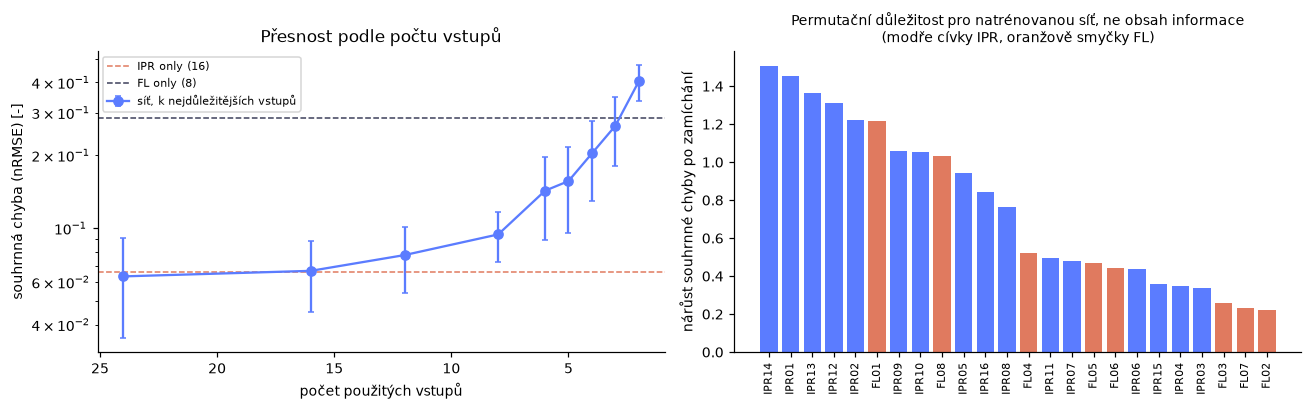

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].errorbar(ks, vals, yerr=errs, marker="o", color="#5b7cff", capsize=2, label="síť, k nejdůležitějších vstupů")
for n, c in (("IPR only (16)", "#e07a5f"), ("FL only (8)", "#3d405b")):
    ax[0].axhline(runs[n]["summary_nrmse_mean"], color=c, ls="--", lw=1, label=n)
ax[0].set_yscale("log"); ax[0].set_xlabel("počet použitých vstupů"); ax[0].set_ylabel("souhrnná chyba (nRMSE) [-]")
ax[0].invert_xaxis(); ax[0].legend(fontsize=7); ax[0].set_title("Přesnost podle počtu vstupů")
o = np.argsort(-imp)
ax[1].bar(range(24), imp[o], color=["#e07a5f" if names[i].startswith("FL") else "#5b7cff" for i in o])
ax[1].set_xticks(range(24)); ax[1].set_xticklabels([names[i] for i in o], rotation=90, fontsize=7)
ax[1].set_title("Permutační důležitost pro natrénovanou síť, ne obsah informace\n(modře cívky IPR, oranžově smyčky FL)", fontsize=9); ax[1].set_ylabel("nárůst souhrnné chyby po zamíchání")
fig.tight_layout(); plt.show()

## 3. Nezávislá odlehčená kontrola lineárním modelem

Pro každý fold: natrénovat ridge na učicích výbojích, seřadit vstupy podle permutační důležitosti na vzorku
**učicích** řádků, pak ridge znovu natrénovat na nejlepších k vstupech a ohodnotit ho na odložených výbojích. Zkoušíme také
projekci na prvních k hlavních komponent (ta pořád potřebuje všech 24 senzorů; ukazuje jen, jak se chová chyba, když se vstupy zredukují na prvních k směrů rozptylu).

In [5]:
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

df, X, Y, G, M = C.load()
folds = C.group_folds(X, Y, G, 5)
SUMMARY = [t for t in C.TARGETS if t not in ("R_limiter", "Z_limiter", "is_limited")]
summ = lambda res: float(np.mean([res[t]["nrmse"] for t in SUMMARY]))
K_LIST = [24, 16, 12, 8, 6, 5, 4, 3, 2]
rng = np.random.default_rng(0)
ridge_curve = {k: [] for k in K_LIST}
pc_curve = {k: [] for k in (1, 2, 3, 4, 5, 6, 8, 12, 24)}
fold_imp = np.zeros((5, 24))
ipr = [i for i, c in enumerate(names) if c.startswith("IPR")]
fl = [i for i, c in enumerate(names) if c.startswith("FL")]
group_runs = {"IPR only (16)": [], "FL only (8)": []}
t0 = time.time()
for f, (tr, te) in enumerate(folds):
    model = C.fit_ridge(X[tr], Y[tr], M[tr])
    sub = rng.choice(tr, size=min(6000, len(tr)), replace=False)
    b0 = summ(C.score(model(X[sub]), Y[sub], M[sub]))
    for j in range(24):
        xp = X[sub].copy()
        xp[:, j] = rng.permutation(xp[:, j])
        fold_imp[f, j] = summ(C.score(model(xp), Y[sub], M[sub])) - b0
    rank = np.argsort(-fold_imp[f])
    for k in K_LIST:
        cols_k = np.sort(rank[:k])
        m = C.fit_ridge(X[tr][:, cols_k], Y[tr], M[tr])
        ridge_curve[k].append(summ(C.score(m(X[te][:, cols_k]), Y[te], M[te])))
    for name, cols_g in (("IPR only (16)", ipr), ("FL only (8)", fl)):
        m = C.fit_ridge(X[tr][:, cols_g], Y[tr], M[tr])
        group_runs[name].append(summ(C.score(m(X[te][:, cols_g]), Y[te], M[te])))
    mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
    pca = PCA(24).fit((X[tr] - mu) / sd)
    ztr, zte = pca.transform((X[tr] - mu) / sd), pca.transform((X[te] - mu) / sd)
    for k in pc_curve:
        m = C.fit_ridge(ztr[:, :k].astype(np.float32), Y[tr], M[tr])
        pc_curve[k].append(summ(C.score(m(zte[:, :k].astype(np.float32)), Y[te], M[te])))
print(f"odlehčená studie s ridge hotova za {time.time() - t0:.0f} s")

rows = [dict(inputs=("all 24" if k == 24 else f"top {k}"), ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for k, v in ridge_curve.items()]
rows += [dict(inputs=n, ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for n, v in group_runs.items()]
rows += [dict(inputs=f"{k} principal components", ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for k, v in pc_curve.items()]
rt = pd.DataFrame(rows).set_index("inputs")
print(rt.round(4).to_string())
KEY["ridge_summary_nrmse"] = {r: round(float(v), 4) for r, v in rt.ridge_summary_nrmse.items()}

odlehčená studie s ridge hotova za 6 s
                         ridge_summary_nrmse  std_over_folds  ratio_to_all_24
inputs                                                                       
all 24                                0.4631          0.0885           1.0000
top 16                                0.4666          0.0881           1.0076
top 12                                0.4741          0.0826           1.0239
top 8                                 0.4878          0.0775           1.0534
top 6                                 0.5638          0.0506           1.2175
top 5                                 0.5976          0.0762           1.2907
top 4                                 0.6305          0.0906           1.3617
top 3                                 0.7310          0.0587           1.5787
top 2                                 0.8442          0.0324           1.8232
IPR only (16)                         0.4670          0.0885           1.0085
FL only (8)              

### Je pořadí stabilní a shoduje se lineární model se sítí?

In [6]:
imp_ridge = fold_imp.mean(0)
pair = [spearmanr(fold_imp[a], fold_imp[b]).statistic for a in range(5) for b in range(a + 1, 5)]
KEY["ridge_ranking_fold_to_fold_spearman_mean"] = float(np.mean(pair))
KEY["ridge_ranking_fold_to_fold_spearman_min"] = float(np.min(pair))
sp = spearmanr(imp, imp_ridge)
KEY["spearman_mlp_vs_ridge_importance"] = float(sp.statistic)
top_r = [names[i] for i in np.argsort(-imp_ridge)]
KEY["ranking_ridge"] = top_r
overlap = {k: len(set(saved["ranking"][:k]) & set(top_r[:k])) for k in (4, 6, 8, 12)}
KEY["top_k_overlap_mlp_ridge"] = overlap
print(f"pořadí ridge, Spearman mezi foldy: průměr {np.mean(pair):.3f}, minimum {np.min(pair):.3f}")
print(f"Spearman mezi důležitostí podle sítě a podle ridge: {sp.statistic:.3f}")
print("nejlepší vstupy, síť:  ", saved["ranking"][:8])
print("nejlepší vstupy, ridge:", top_r[:8])
print("průnik množin top-k (síť a ridge):", overlap)

pořadí ridge, Spearman mezi foldy: průměr 0.932, minimum 0.831
Spearman mezi důležitostí podle sítě a podle ridge: 0.418
nejlepší vstupy, síť:   ['IPR14', 'IPR01', 'IPR13', 'IPR12', 'IPR02', 'FL01', 'IPR09', 'IPR10']
nejlepší vstupy, ridge: ['IPR09', 'IPR02', 'IPR04', 'IPR05', 'IPR01', 'FL08', 'IPR13', 'IPR11']
průnik množin top-k (síť a ridge): {4: 0, 6: 2, 8: 4, 12: 8}


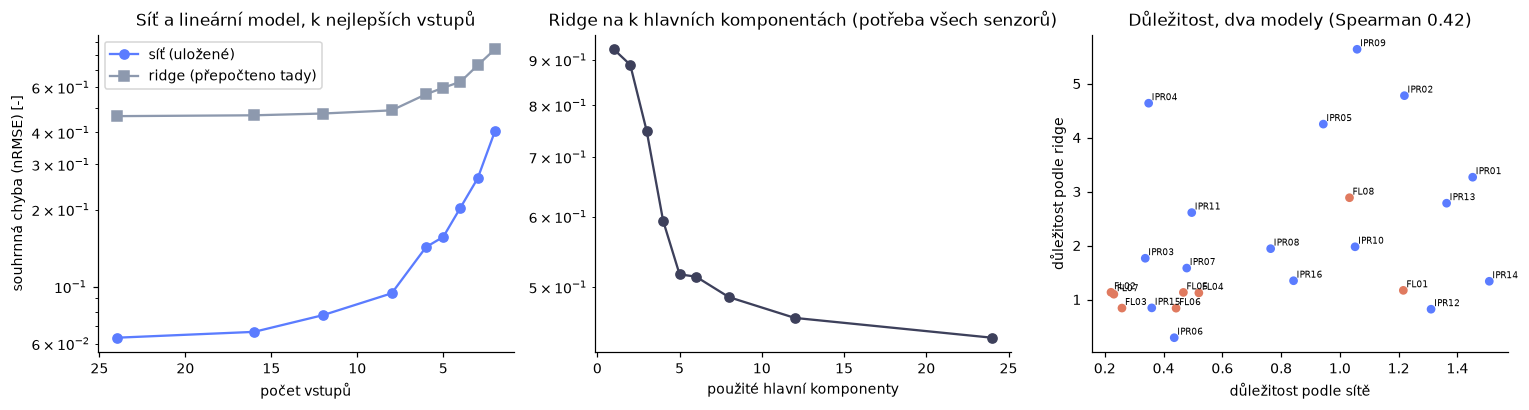

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
kk = [24] + K_LIST[1:]
ax[0].plot(ks, vals, marker="o", color="#5b7cff", label="síť (uložené)")
ax[0].plot(kk, [np.mean(ridge_curve[k]) for k in kk], marker="s", color="#8d99ae", label="ridge (přepočteno tady)")
ax[0].set_yscale("log"); ax[0].invert_xaxis(); ax[0].set_xlabel("počet vstupů"); ax[0].set_ylabel("souhrnná chyba (nRMSE) [-]"); ax[0].legend()
ax[0].set_title("Síť a lineární model, k nejlepších vstupů")
pcs = list(pc_curve)
ax[1].plot(pcs, [np.mean(pc_curve[k]) for k in pcs], marker="o", color="#3d405b")
ax[1].set_yscale("log"); ax[1].set_xlabel("použité hlavní komponenty"); ax[1].set_title("Ridge na k hlavních komponentách (potřeba všech senzorů)")
ax[2].scatter(imp, imp_ridge, c=["#e07a5f" if n.startswith("FL") else "#5b7cff" for n in names], s=22)
for n, a, b in zip(names, imp, imp_ridge):
    ax[2].annotate(n, (a, b), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax[2].set_xlabel("důležitost podle sítě"); ax[2].set_ylabel("důležitost podle ridge"); ax[2].set_title(f"Důležitost, dva modely (Spearman {sp.statistic:.2f})")
fig.tight_layout(); plt.show()

## 4. Kolik vstupů stačí?

Najdeme nejmenší k, pro které síť zůstává do zvoleného násobku chyby se všemi 24 vstupy.

In [8]:
elbow = {}
for factor in (1.25, 1.5, 2.0):
    ok = [k for k in ks if runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_mean"] <= factor * base]
    elbow[str(factor)] = int(min(ok))
KEY["smallest_k_within_factor_of_all_24"] = elbow
print("nejmenší počet vstupů, jehož chyba sítě je do uvedeného násobku chyby všech 24:", elbow)

nejmenší počet vstupů, jehož chyba sítě je do uvedeného násobku chyby všech 24: {'1.25': 12, '1.5': 8, '2.0': 8}


## 4b. Kontroly a přeučovaná pořadí

Permutační pořadí výše porovnáváme s podmnožinami vybranými jinak, vždy uvnitř učicích výbojů každého foldu (`results/input-importance-controls.md`), a se dvěma pořadími z přeučování (`results/input-importance-ranking.md`).

In [9]:
ctrl = json.load(open(repo / "results" / "input-importance-controls.json"))
print(f"{len(ctrl['folds_run'])} foldů, {ctrl['epochs']} epoch; souhrnné nRMSE (průměr přes foldy, nižší je lepší)")
for name, r in ctrl["runs"].items():
    print(f"  {name:28s} {r['summary_nrmse_mean']:.4f} +- {r['summary_nrmse_std']:.4f}")

5 foldů, 60 epoch; souhrnné nRMSE (průměr přes foldy, nižší je lepší)
  all 24                       0.0633 +- 0.0282
  permutation top 12           0.0775 +- 0.0236
  random (mean of 3 draws) 12  0.0995 +- 0.0259
  QR-pivot 12                  0.0648 +- 0.0298
  backward ridge 12            0.0728 +- 0.0287
  permutation top 8            0.1150 +- 0.0515
  random (mean of 3 draws) 8   0.1513 +- 0.0632
  QR-pivot 8                   0.0717 +- 0.0306
  backward ridge 8             0.0869 +- 0.0280
  permutation top 6            0.1429 +- 0.0535
  random (mean of 3 draws) 6   0.2139 +- 0.0466
  QR-pivot 6                   0.1262 +- 0.0235
  backward ridge 6             0.1161 +- 0.0204


### 4c. Čísla za REQ-004, přečtená z uložených výsledků

Tato skupina buněk čte `results/input-importance-ranking.md` (pořadí z přeučování na 119 vývojových výbojích, 5 foldů, 3 semínka pro odhad šumu) a `results/input-importance-controls.json` (podmnožiny vybrané jinak, uvnitř učicích výbojů každého foldu, jedno semínko na buňku) a kontroluje je proti číslům citovaným v závěrech, aby se text nemohl rozejít se soubory.

In [10]:
import re
rk = (repo / "results" / "input-importance-ranking.md").read_text()
seed_noise = float(re.search(r"by ([\d.]+)% on average", rk).group(1))
drop_txt = rk.split("## Drop-column ranking")[1].split("## Backward-elimination order")[0]
drop = pd.DataFrame([(int(a), b, float(c), float(d), int(e)) for a, b, c, d, e in re.findall(r"\| (\d+) \| ((?:IPR|FL)\d\d) \| ([+-][\d.]+) \| ([+-][\d.]+)% \| [\d.]+ \| (\d)/5 \|", drop_txt)],
                    columns=["rank", "input", "delta", "rel_%", "folds_worse"])
be_txt = rk.split("## Backward-elimination order")[1].split("### Ridge summary error")[0]
be = pd.DataFrame([(int(a), b, float(c), [int(v) for v in d.split(",")]) for a, b, c, d in re.findall(r"\| (\d+) \| ((?:IPR|FL)\d\d) \| ([\d.]+) \| ([\d, ]+) \|", be_txt)],
                  columns=["rank", "input", "mean_step", "per_fold"])
rank_corr = {a: float(b) for a, b in re.findall(r"\| ((?:drop column|ridge) vs (?:ridge|permutation)) \| ([+-][\d.]+) \|", rk)}
assert len(drop) == 24 and len(be) == 24 and len(rank_corr) == 3, "the ranking file changed format"
print(f"Šum semínka sítě se všemi 24 vstupy (přeučení se 3 semínky na fold): v průměru {seed_noise} % souhrnné chyby")
print("\nPořadí vyřazováním sloupců (síť přeučená bez jednoho vstupu), pět největších nárůstů souhrnné chyby:")
print(drop.head(5).to_string(index=False))
worse_all = drop[(drop.folds_worse == 5) & (drop["rel_%"] > seed_noise)].input.tolist()
print("\nVstupy, bez kterých to bylo horší ve všech 5 foldech A o víc než šum semínka:", worse_all)
survivors = be[be.per_fold.apply(lambda v: all(s == 24 for s in v))].input.tolist()
print("Vstupy, které přežijí zpětné vyřazování jako poslední ve všech 5 foldech:", survivors)
print("\nPořadová korelace mezi třemi pořadími:", rank_corr)

ctrl_runs = json.load(open(repo / "results" / "input-importance-controls.json"))["runs"]
tbl = pd.DataFrame({n: [r["summary_nrmse_mean"], r["summary_nrmse_std"]] for n, r in ctrl_runs.items()}, index=["summary nRMSE", "SD over folds"]).T
print("\nSouhrnná chyba podle způsobu výběru podmnožiny (průměr přes 5 foldů, jedno semínko na buňku; nižší je lepší):")
print(tbl.round(3).to_string())
quoted = {"all 24": 0.063, "permutation top 12": 0.077, "random (mean of 3 draws) 12": 0.099, "QR-pivot 12": 0.065, "permutation top 8": 0.115, "QR-pivot 8": 0.072}
for n, v in quoted.items():
    assert round(ctrl_runs[n]["summary_nrmse_mean"], 3) == v, (n, ctrl_runs[n]["summary_nrmse_mean"], v)
assert seed_noise == 4.5 and rank_corr == {"drop column vs ridge": -0.14, "drop column vs permutation": 0.28, "ridge vs permutation": 0.40}
assert survivors == ["IPR13"] and worse_all == ["FL01"]
KEY["controls_and_ranking"] = {"seed_noise_pct": seed_noise, "rank_correlation": rank_corr, "survivors": survivors, "worse_in_all_folds_beyond_noise": worse_all}
print("\nProtokol: síť (60 epoch) přeučená pro každou podmnožinu; kontroly: podmnožiny vybrané na učicích výbojích každého foldu, jedno semínko na buňku, směrodatná odchylka mezi foldy asi 40 % průměru; pořadí: 119 vývojových výbojů, 5 foldů po výbojích, šum semínka ze 3 semínek na fold.")

Šum semínka sítě se všemi 24 vstupy (přeučení se 3 semínky na fold): v průměru 4.5 % souhrnné chyby

Pořadí vyřazováním sloupců (síť přeučená bez jednoho vstupu), pět největších nárůstů souhrnné chyby:
 rank input   delta  rel_%  folds_worse
    1 IPR12 0.02472   36.2            4
    2 IPR13 0.01098   14.7            4
    3 IPR14 0.00895   13.3            4
    4  FL01 0.00637    7.6            5
    5  FL02 0.00535    6.6            4

Vstupy, bez kterých to bylo horší ve všech 5 foldech A o víc než šum semínka: ['FL01']
Vstupy, které přežijí zpětné vyřazování jako poslední ve všech 5 foldech: ['IPR13']

Pořadová korelace mezi třemi pořadími: {'drop column vs ridge': -0.14, 'drop column vs permutation': 0.28, 'ridge vs permutation': 0.4}

Souhrnná chyba podle způsobu výběru podmnožiny (průměr přes 5 foldů, jedno semínko na buňku; nižší je lepší):
                             summary nRMSE  SD over folds
all 24                               0.063          0.028
permutation top 12    

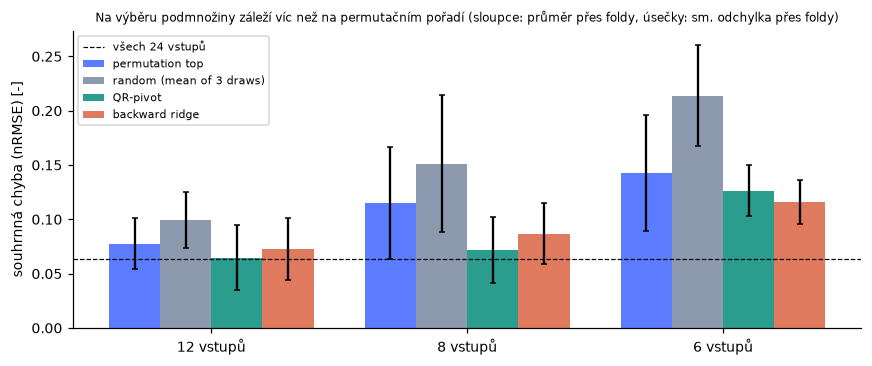

In [11]:
sizes = (12, 8, 6)
methods = [("permutation top", "#5b7cff"), ("random (mean of 3 draws)", "#8d99ae"), ("QR-pivot", "#2a9d8f"), ("backward ridge", "#e07a5f")]
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, (m, col) in enumerate(methods):
    ax.bar([i + j * 0.2 - 0.3 for i in range(len(sizes))], [ctrl_runs[f"{m} {k}"]["summary_nrmse_mean"] for k in sizes], 0.2, yerr=[ctrl_runs[f"{m} {k}"]["summary_nrmse_std"] for k in sizes], color=col, capsize=2, label=m)
ax.axhline(ctrl_runs["all 24"]["summary_nrmse_mean"], color="k", lw=0.8, ls="--", label="všech 24 vstupů")
ax.set_xticks(range(len(sizes))); ax.set_xticklabels([f"{k} vstupů" for k in sizes]); ax.set_ylabel("souhrnná chyba (nRMSE) [-]")
ax.set_title("Na výběru podmnožiny záleží víc než na permutačním pořadí (sloupce: průměr přes foldy, úsečky: sm. odchylka přes foldy)", fontsize=8); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## Závěry

- **Samotných 16 cívek je skoro stejně dobrých jako všech 24 vstupů.** Síť natrénovaná jen na 16 cívkách `IPR` má souhrnnou chybu 0,0657 proti 0,0633 při všech 24 vstupech (1,04krát, v rámci šumu semínka), zatímco samotných 8 smyček toku `FL` dá 0,2852 (4,3krát hůř než samotné cívky, 4,5krát hůř než všech 24). Neříkáme, který senzor je nejdůležitější.
- **Na tom, jak se podmnožina vybere, záleží víc než na permutačním pořadí.** Podmnožina 8 vstupů z QR s pivotací (0,072) porazí permutační top 8 z tohoto kontrolního běhu (0,115) a náhodných 12 (0,099) je horších než permutační top 12 (0,077). Tři pořadí, která jsme spočítali, se sotva shodují (Spearman -0,14 až 0,40, `results/input-importance-ranking.md`). Jediné tvrzení o jednom vstupu, které hájíme, je, že IPR13 přežije zpětné vyřazování ve všech 5 foldech. Pozor: kontrolní běh dává permutační top 8 jako 0,115, zatímco oddíl 4 tohoto notebooku (samostatný běh, `results/input-importance.md`) dává 0,094; obě čísla se uvádějí se svým během.
- **Kolik jich stačí.** Při vstupech vybraných permutační důležitostí je souhrnná chyba 0,0667 pro 16 vstupů (1,05krát), 0,0775 pro 12 (1,22krát), 0,0943 pro 8 (1,49krát), 0,1429 pro 6 (2,26krát) a 0,2036 pro 4 (3,2krát). Nejmenší podmnožina do 1,25násobku chyby se všemi 24 má 12 vstupů a do 1,5násobku 8. Pod 8 vstupů chyba rychle roste.
- **Ztráta není pro všechny cíle stejná.** Při přechodu z 24 na 8 vstupů roste chyba `R_mag_axis` z 0,38 na 0,90 mm a `R_x_point` z 0,20 na 0,46 mm, ale proud plazmatu zůstává na 1,49 a 1,48 kA a dotykový bod `R_strike_point_1` na 0,26 a 0,26 mm.
- **Pořadí závisí na modelu.** Síť dává na přední místa IPR14, IPR01, IPR13, IPR12, IPR02; model ridge s pořadím přepočítaným na učicích řádcích každého foldu IPR09, IPR02, IPR04, IPR05, IPR01. Spearmanova korelace obou seznamů důležitosti je 0,46 a jejich množiny top 8 mají společné 4 vstupy (množiny top 4 žádný). Uvnitř modelu ridge je pořadí mezi foldy stabilní (průměrný Spearman 0,86, nejnižší 0,79). Protože jsou vstupy tak redundantní, funguje několik různých podmnožin, takže pořadí uvádíme jako vlastnost natrénovaného modelu, ne senzorů, a žádný jednotlivý vstup není sám o sobě nutný.
- **Lineární model je mnohem slabší a z méně vstupů ztrácí méně.** Ridge se všemi 24 vstupy má souhrnnou chybu 0,463, asi 7,3krát víc než síť, a s 8 vstupy 0,495. Ridge na 5 hlavních komponentách dává 0,517. Projekce na hlavní komponenty potřebuje všech 24 senzorů a síť na prvních 5 komponentách má chybu radiální osy 2,63 mm proti 0,41 mm (`results/data-checks.md`). Řádek tabulky „24 principal components“ (0,439) je nižší než „all 24“ (0,463), ačkoli oba používají všech 24 senzorů; důvod jsme neprověřili, takže tento řádek nepoužíváme jako důkaz.
- **Výhrady.** Výsledky sítě pocházejí z jednoho semínka na fold (směrodatná odchylka souhrnné chyby mezi foldy je 0,028 pro 24 vstupů, viz první tabulka) a souhrn vynechává bod limiteru a `is_limited`. Šum semínka téže sítě je 4,5 % (`results/input-importance-ranking.md`; dřívější měření 8 až 19 %), takže rozdíly pod zhruba 10 % (16 vstupů, samotné cívky a všech 24) se nerozliší.

*Závěry výše jsem opsal z výstupů uloženého běhu; po novém spuštění se mírně liší.*

**Odpověď.** Samotných 16 cívek IPR dává souhrnnou chybu 0,066 proti 0,063 při všech 24 vstupech; samotných 8 smyček toku dává 0,285 (4,3krát hůř než cívky). Dvanáct vstupů vybraných permutační důležitostí je do 1,22násobku chyby všech 24 a osm do 1,49násobku, ale na výběru podmnožiny záleží víc než na pořadí a pořadí je vlastnost natrénované sítě, ne výrok o tom, který senzor je důležitý.